## Health study - Part 1 (del1)
### Descriptive analysis of health data 

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)

### 1. Data exploration

In [2]:
df = pd.read_csv("data/health_study_data.csv")
df.head()

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


In [3]:
df.shape

(800, 9)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


### 2. Descriptive statistics

In [5]:
columns = ["age", "weight", "height", "systolic_bp", "cholesterol"]
df[columns].agg(["mean", "median", "min", "max"]).round(2)

,age,weight,height,systolic_bp,cholesterol
mean,49.43,73.41,171.85,149.18,4.93
median,50.00,73.20,171.35,149.40,4.97
min,18.00,33.70,144.40,106.80,2.50
max,90.00,114.40,200.40,185.90,7.88


#### Interpretation of initial data 
The dataset contains 800 participants between 18 and 90 years old. The average age is 49.43 years, and the median age is 50 years.
The mean and median are quite similar for all five variables. This may mean that the data is fairly evenly distributed, but we need to look at graphs to understand the distributions better.

### 3. Data visualization

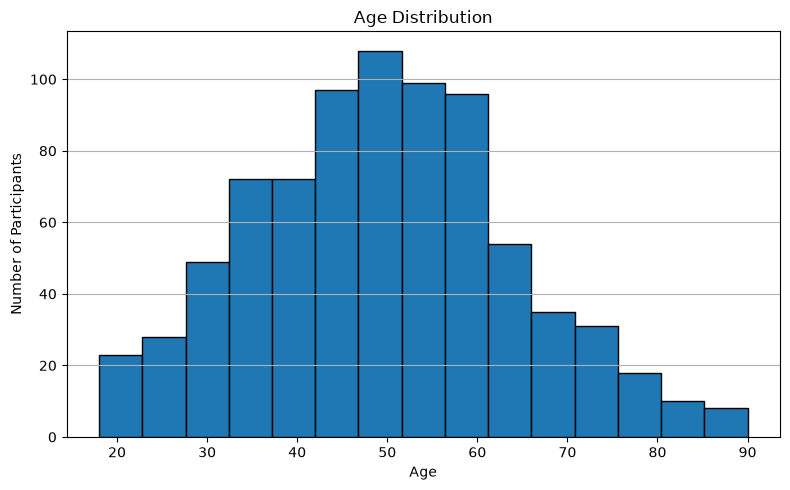

In [6]:
plt.figure(figsize=(8, 5))

plt.hist(df["age"], bins=15, edgecolor="black")

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Participants")
plt.grid(axis="y")

plt.tight_layout()
plt.show()

#### Interpretation of age distribution

The histogram shows that most participants are between 35 and 60 years old. The highest number of participants is around the age of 50.
There are fewer younger and older participants. The distribution is roughly bell-shaped, which fits with the mean age of 49.43 years and the median age of 50 years.

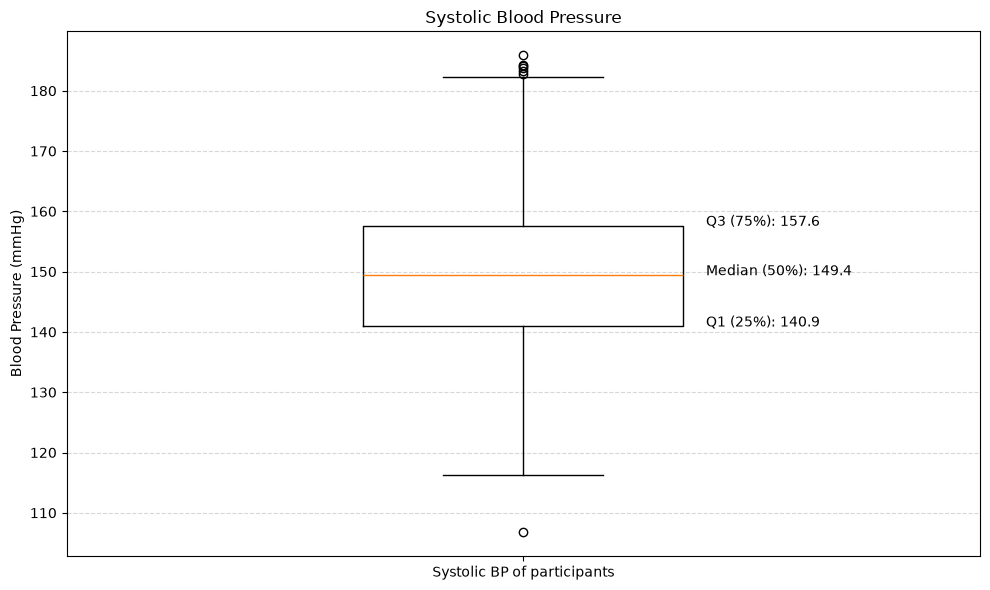

In [7]:
bp = df["systolic_bp"]

q1 = bp.quantile(0.25)
median = bp.median()
q3 = bp.quantile(0.75)

plt.figure(figsize=(10, 6))

plt.boxplot(bp, widths=0.35)

plt.title("Systolic Blood Pressure")
plt.ylabel("Blood Pressure (mmHg)")
plt.xticks([1], ["Systolic BP of participants"])

plt.annotate(f"Q1 (25%): {q1:.1f}",
             xy=(1.2, q1), fontsize=10)

plt.annotate(f"Median (50%): {median:.1f}",
             xy=(1.2, median), fontsize=10)

plt.annotate(f"Q3 (75%): {q3:.1f}",
             xy=(1.2, q3), fontsize=10)

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

#### Interpretation of systolic blood pressure
The median systolic blood pressure is 149.4 mmHg.
The middle 50% of the participants have blood pressure values between 140.9 and 157.6 mmHg.
There are also a few outliers, with both unusually high and low blood pressure values.

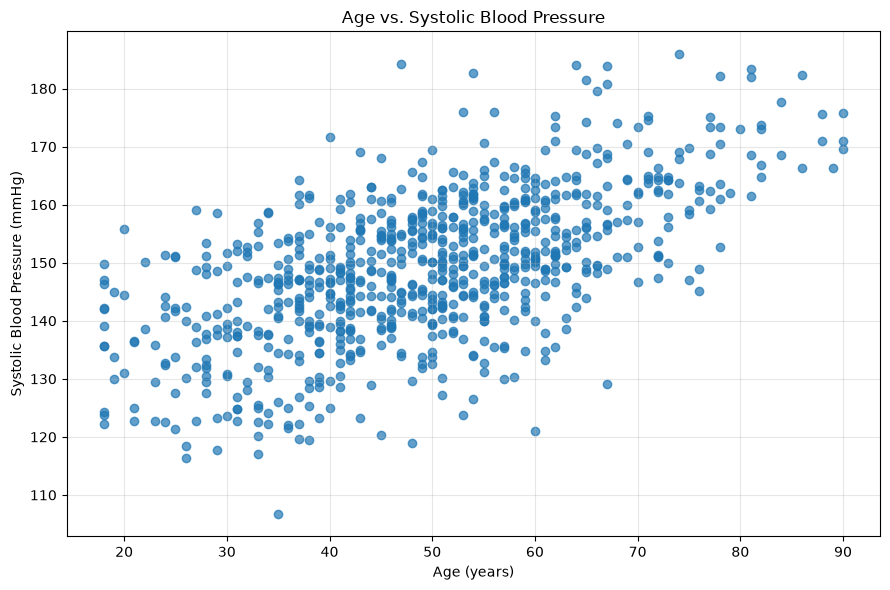

In [8]:
plt.figure(figsize=(9, 6))

plt.scatter(df["age"], df["systolic_bp"], alpha=0.7)

plt.title("Age vs. Systolic Blood Pressure")
plt.xlabel("Age (years)")
plt.ylabel("Systolic Blood Pressure (mmHg)")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Interpretation of age vs. systolic blood pressure

The scatter plot shows a positive relationship between age and systolic blood pressure. Older participants generally have higher blood pressure than younger participants.
However, the points are quite spread out, which means that people of the same age can have different blood pressure values.
This suggests a relationship between age and blood pressure, but it does not prove that age causes higher blood pressure.

### 4. Disease prevalence and stimulation
#### Disease prevalence

In [9]:
print(df["disease"].value_counts())

prevalence = df["disease"].mean()

print(f"\nDisease prevalence: {prevalence * 100:.2f}%")

disease
0    753
1     47
Name: count, dtype: int64

Disease prevalence: 5.88%


#### Simulation of 1000 participants 

In [10]:
simulated = np.random.binomial(n=1, p=prevalence, size=1000)

print("Simulated cases:", simulated.sum())
print(f"Simulated prevalence: {simulated.mean() * 100:.2f}%")

Simulated cases: 56
Simulated prevalence: 5.60%


#### Interpretation of the simulation

The disease prevalence in the original dataset is 5.88%.
Using this probability, 1,000 participants were simulated with NumPy. The simulated prevalence may be slightly higher or lower than the original prevalence.
This is expected because the simulation uses random values. The results can vary, even when the probability stays the same.

### 5. Confidence interval for systolic blood pressure

In [11]:
bp = df["systolic_bp"]

mean_bp = bp.mean()
std_bp = bp.std()
n = len(bp)

se = std_bp / np.sqrt(n)

margin = 1.96 * se

ci_lower = mean_bp - margin
ci_upper = mean_bp + margin

print(f"Mean blood pressure: {mean_bp:.2f} mmHg")
print(f"Standard error: {se:.2f} mmHg")
print(f"95% Confidence Interval: [{ci_lower:.2f}, {ci_upper:.2f}] mmHg")

Mean blood pressure: 149.18 mmHg
Standard error: 0.45 mmHg
95% Confidence Interval: [148.29, 150.07] mmHg


#### Interpretation of the confidence interval
The average systolic blood pressure is 149.18 mmHg.
The 95% confidence interval is between 148.29 and 150.07 mmHg. This interval gives an estimate of the average systolic blood pressure in the population.
If we repeated the study many times, about 95% of the calculated intervals would contain the true population mean.

### 6. Hypothesis testing

#### Blood pressure: smokers vs. non-smokers

In [12]:
df.groupby("smoker")["systolic_bp"].mean().round(2)

smoker
No     149.05
Yes    149.52
Name: systolic_bp, dtype: float64

In [13]:
smokers = df[df["smoker"] == "Yes"]["systolic_bp"]
non_smokers = df[df["smoker"] == "No"]["systolic_bp"]

t_stat, p_value = stats.ttest_ind(
    smokers,
    non_smokers,
    equal_var=False,
    alternative="greater"
)

print(f"T-statistic: {t_stat:.2f}")
print(f"P-value: {p_value:.4f}")

T-statistic: 0.45
P-value: 0.3264


#### Interpretation of the hypothesis test

The average systolic blood pressure is 149.52 mmHg for smokers and 149.05 mmHg for non-smokers.
A one-sided Welch's t-test was used to check if smokers have higher average blood pressure than non-smokers.
The p-value is 0.3264, which is higher than 0.05. This means the result is not statistically significant.
We do not have enough evidence to conclude that smokers have higher average systolic blood pressure than non-smokers.